In [1]:
#library 
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
#load data 
df = pd.read_csv('wellness.csv')
df.head()

,Employee_ID,Department,Job_Level,Work_Model,Age,Tenure_Years,Primary_Stressor_Category,Financial_Stress_Score_1_10,Mental_Burnout_Score_1_10,Body_Image_Dissatisfaction_Score_1_10,Composite_Risk_Score,Avg_Sleep_Hours_Per_Night,Unplanned_Sick_Days_Last_12M,Intervention_Urgency_Tier,Descriptive_Wellness_Assessment,Recommended_Thrive500_Intervention
0,EMP-0001,Product & Design,Entry-Level / Associate,Hybrid,40,2.7,Financial Stress (Money),8,5,3,5.3,6.1,4,Elevated Risk (Targeted Support),Struggling with monthly debt repayments and hi...,Q4 Financial Literacy Track + 1-on-1 Debt & Bu...
1,EMP-0002,Sales & Marketing,Entry-Level / Associate,Hybrid,35,6.9,Financial Stress (Money),10,8,4,7.3,5.8,6,High Priority (Immediate Intervention),Struggling with monthly debt repayments and hi...,Q4 Financial Literacy Track + 1-on-1 Debt & Bu...
2,EMP-0003,Product & Design,Senior Specialist,Remote,40,1.9,Financial Stress (Money),9,5,3,5.7,5.7,6,Elevated Risk (Targeted Support),High family healthcare and childcare expenses ...,1-on-1 Financial Coaching + Flexible Wellness ...
3,EMP-0004,Operations & Logistics,Team Lead / Manager,Hybrid,30,9.3,Financial Stress (Money),9,5,5,6.3,6.5,8,Elevated Risk (Targeted Support),High family healthcare and childcare expenses ...,1-on-1 Financial Coaching + Flexible Wellness ...
4,EMP-0005,Sales & Marketing,Entry-Level / Associate,On-Site,25,6.5,Financial Stress (Money),9,5,4,6.0,6.6,7,Elevated Risk (Targeted Support),High family healthcare and childcare expenses ...,Emergency Savings Workshop + Tax/Retirement Op...


In [3]:
#quality check 
print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
print("Missing Values per Column:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("Duplicate Employee IDs:", df.duplicated(subset=['Employee_ID']).sum())

Dataset Dimensions: 300 rows, 16 columns
Missing Values per Column:
 Series([], dtype: int64)
Duplicate Employee IDs: 0


In [4]:
# 3. Validate score boundaries (1 to 10 scale)
score_cols = [
    'Financial_Stress_Score_1_10', 
    'Mental_Burnout_Score_1_10', 
    'Body_Image_Dissatisfaction_Score_1_10'
]
assert df[score_cols].min().min() >= 1 and df[score_cols].max().max() <= 10, "Score out of bounds!"

In [5]:
# 1. Cast categorical variables for memory efficiency and ordered plotting
categorical_cols = ['Department', 'Job_Level', 'Work_Model', 'Primary_Stressor_Category', 'Intervention_Urgency_Tier']
for col in categorical_cols:
    df[col] = df[col].astype('category')

# 2. Recompute & verify Composite Risk Score
df['Composite_Risk_Score'] = df[score_cols].mean(axis=1).round(1)

# 3. Engineer clinical & financial baseline flags
# Clinical sleep deprivation threshold (< 6.0 hours/night)
df['Sleep_Deprived_Flag'] = np.where(df['Avg_Sleep_Hours_Per_Night'] < 6.0, 1, 0)

# Absenteeism payroll loss ($150/day baseline from Thrive 500 CFO model)
df['Estimated_Sick_Day_Cost_USD'] = df['Unplanned_Sick_Days_Last_12M'] * 150

# High absenteeism flag (> 6.0 company baseline sick days)
df['Excess_Absenteeism_Flag'] = np.where(df['Unplanned_Sick_Days_Last_12M'] > 6, 1, 0)

In [6]:
num_cols = [
    'Age', 'Tenure_Years', 'Financial_Stress_Score_1_10', 
    'Mental_Burnout_Score_1_10', 'Body_Image_Dissatisfaction_Score_1_10',
    'Composite_Risk_Score', 'Avg_Sleep_Hours_Per_Night', 
    'Unplanned_Sick_Days_Last_12M', 'Estimated_Sick_Day_Cost_USD'
]

baseline_stats = df[num_cols].agg(['count', 'mean', 'median', 'std', 'min', 'max']).T.round(2)
print(baseline_stats)

                                       count     mean   median     std    min  \
Age                                    300.0    39.38    40.00    9.49   23.0   
Tenure_Years                           300.0     4.93     4.75    2.61    0.6   
Financial_Stress_Score_1_10            300.0     6.19     6.00    2.38    3.0   
Mental_Burnout_Score_1_10              300.0     7.35     7.00    1.52    5.0   
Body_Image_Dissatisfaction_Score_1_10  300.0     6.26     6.00    2.19    3.0   
Composite_Risk_Score                   300.0     6.60     6.70    0.64    5.0   
Avg_Sleep_Hours_Per_Night              300.0     5.85     5.90    0.69    4.2   
Unplanned_Sick_Days_Last_12M           300.0     7.14     7.00    2.11    4.0   
Estimated_Sick_Day_Cost_USD            300.0  1071.50  1050.00  317.17  600.0   

                                          max  
Age                                      56.0  
Tenure_Years                              9.5  
Financial_Stress_Score_1_10              10.0

In [7]:
cohort_summary = df.groupby('Primary_Stressor_Category', observed=False).agg(
    Headcount=('Employee_ID', 'count'),
    Avg_Composite_Risk=('Composite_Risk_Score', 'mean'),
    Avg_Sleep_Hrs=('Avg_Sleep_Hours_Per_Night', 'mean'),
    Sleep_Deprived_Pct=('Sleep_Deprived_Flag', lambda x: round(x.mean() * 100, 1)),
    Avg_Sick_Days=('Unplanned_Sick_Days_Last_12M', 'mean'),
    Total_Sick_Cost_USD=('Estimated_Sick_Day_Cost_USD', 'sum'),
    High_Priority_Cases=('Intervention_Urgency_Tier', lambda x: (x == 'High Priority (Immediate Intervention)').sum())
).round(2)

print(cohort_summary)

                                Headcount  Avg_Composite_Risk  Avg_Sleep_Hrs  \
Primary_Stressor_Category                                                      
Body Image & Physical Vitality        100                6.63           6.31   
Financial Stress (Money)              100                6.69           5.97   
Mental Health & Burnout               100                6.48           5.26   

                                Sleep_Deprived_Pct  Avg_Sick_Days  \
Primary_Stressor_Category                                           
Body Image & Physical Vitality                28.0           5.88   
Financial Stress (Money)                      45.0           6.66   
Mental Health & Burnout                       86.0           8.89   

                                Total_Sick_Cost_USD  High_Priority_Cases  
Primary_Stressor_Category                                                 
Body Image & Physical Vitality                88200                   43  
Financial Stress (Money)    

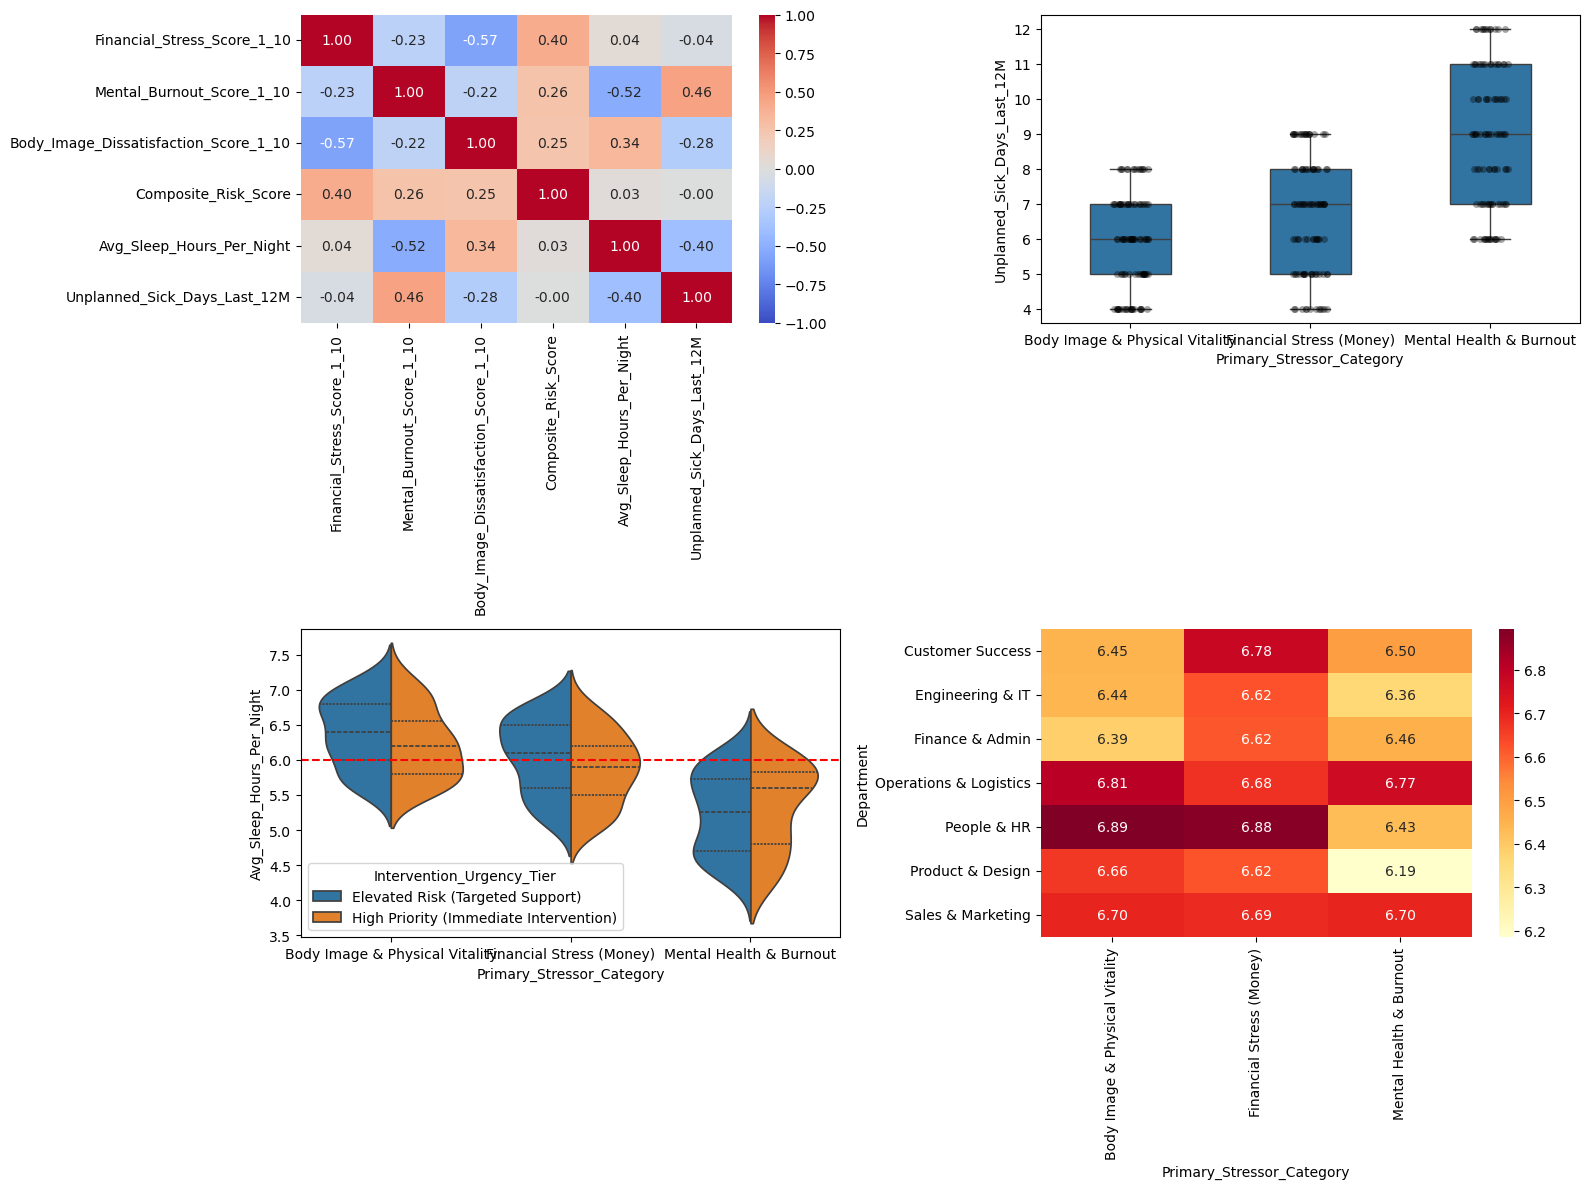

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Panel A: Pearson Correlation Matrix
corr_cols = [
    'Financial_Stress_Score_1_10', 'Mental_Burnout_Score_1_10', 
    'Body_Image_Dissatisfaction_Score_1_10', 'Composite_Risk_Score', 
    'Avg_Sleep_Hours_Per_Night', 'Unplanned_Sick_Days_Last_12M'
]
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0, 0])

# Panel B: Boxplot + Jittered Stripplot of Unplanned Sick Days by Stressor
sns.boxplot(data=df, x='Primary_Stressor_Category', y='Unplanned_Sick_Days_Last_12M', width=0.45, ax=axes[0, 1])
sns.stripplot(data=df, x='Primary_Stressor_Category', y='Unplanned_Sick_Days_Last_12M', color='black', alpha=0.35, ax=axes[0, 1])

# Panel C: Split Violin Plot of Nightly Sleep by Stressor & Urgency Tier
sns.violinplot(
    data=df, x='Primary_Stressor_Category', y='Avg_Sleep_Hours_Per_Night',
    hue='Intervention_Urgency_Tier', split=True, inner='quartile', ax=axes[1, 0]
)
axes[1, 0].axhline(6.0, color='red', linestyle='--', label='Clinical Sleep Deprivation (<6.0h)')

# Panel D: Department x Stressor Composite Risk Heatmap
pivot_dept = df.pivot_table(index='Department', columns='Primary_Stressor_Category', values='Composite_Risk_Score', aggfunc='mean', observed=False)
sns.heatmap(pivot_dept, annot=True, fmt='.2f', cmap='YlOrRd', ax=axes[1, 1])

plt.tight_layout()
plt.savefig('thrive500_pre_intervention_eda_suite.png', dpi=300)